# Phase 1 — Synthetic Data Generation and Preliminary Analysis

**Team 15 · Dynamical Systems in Machine Learning**

**Goal.** Generate two benchmark nonlinear dynamical systems, create realistic noisy measurements, and save reproducible data for the linear state-space model (LDS) and piecewise-linear recurrent neural network (PLRNN).

This notebook is intentionally limited to **data generation**. Model fitting and dynamical reconstruction come later. All code, figures and conclusions are written in English for inclusion in the final report.

**Reference:** Koppe et al. (2019), *Identifying nonlinear dynamical systems via generative recurrent neural networks with applications to fMRI*, PLOS Computational Biology, Fig. 4 and Methods.


## 1. Mathematical models

### Lorenz system

The Lorenz system is a three-dimensional nonlinear system that exhibits a chaotic attractor for the parameters below:

$$
\begin{aligned}
\frac{dx}{dt} &= \sigma(y-x),\\
\frac{dy}{dt} &= x(\rho-z)-y,\\
\frac{dz}{dt} &= xy-\beta z.
\end{aligned}
$$

We set $\sigma=10$, $\rho=28$, and $\beta=8/3$ as in Fig. 4 of the paper.

### Van der Pol oscillator

The Van der Pol oscillator is a nonlinear system with a stable periodic orbit (a **limit cycle**):

$$
\begin{aligned}
\frac{dx}{dt} &= y,\\
\frac{dy}{dt} &= -\mu(x^2-1)y-\omega^2x.
\end{aligned}
$$

We set $\mu=2$ and $\omega=1$ as in Fig. 4 of the paper.

We solve these differential equations numerically using an adaptive Runge–Kutta integrator (`scipy.integrate.solve_ivp`). The sampling intervals and transient-discard durations are our own explicit experiment settings, not necessarily those of the paper.


In [1]:
# Run this notebook from the repository root or from the notebooks/ directory.
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if not (ROOT / "src" / "data" / "lorenz.py").exists():
    raise FileNotFoundError(
        "Could not find src/data/lorenz.py. Open the repository in VS Code, "
        "or change the working directory to the repository root first."
    )
sys.path.insert(0, str(ROOT))

from src.data.lorenz import simulate_lorenz
from src.data.van_der_pol import simulate_van_der_pol
from src.data.preprocessing import make_dataset, save_dataset, load_dataset

DATA_DIR = ROOT / "data" / "synthetic"
FIGURE_DIR = ROOT / "results" / "figures"
DATA_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
OBSERVATION_NOISE_STD = 0.10  # 10% of per-channel clean training standard deviation
TRAIN_FRACTION = 0.70
print("Repository root:", ROOT)


Repository root: C:\PLRNN-Project


## 2. Numerical simulation

We discard an initial transient ("burn-in") to concentrate on the long-term behavior. We retain exactly 1,000 samples for each system. The code keeps **clean states** separate from **observed measurements**.

In [2]:
lorenz_time, lorenz_states = simulate_lorenz(
    n_steps=1000,
    dt=0.02,
    burn_in=5.0,
    initial_state=(1.0, 1.0, 1.0),
    sigma=10.0, rho=28.0, beta=8.0 / 3.0,
)

vdp_time, vdp_states = simulate_van_der_pol(
    n_steps=1000,
    dt=0.05,
    burn_in=15.0,
    initial_state=(2.0, 0.0),
    mu=2.0, omega=1.0,
)

assert lorenz_states.shape == (1000, 3)
assert vdp_states.shape == (1000, 2)
assert np.isfinite(lorenz_states).all()
assert np.isfinite(vdp_states).all()
print("Lorenz:", lorenz_states.shape, "| time span:", lorenz_time[-1])
print("Van der Pol:", vdp_states.shape, "| time span:", vdp_time[-1])


Lorenz: (1000, 3) | time span: 19.98
Van der Pol: (1000, 2) | time span: 49.95


## 3. Observation noise and normalization

We simulate a measurement process:

$$
\mathbf{x}^{\mathrm{obs}}_t=\mathbf{x}^{\mathrm{clean}}_t+\boldsymbol{\eta}_t,
\qquad \boldsymbol{\eta}_t \sim \mathcal{N}(\mathbf{0},\Gamma).
$$

The measurement-noise standard deviation is 10% of the clean training standard deviation in each channel. We then calculate the mean and standard deviation from **only the noisy training segment** (first 70%) and use those same values for both training and later observations, to avoid leakage.

**Important limitation:** This is *observation noise*. Koppe et al. also study *process noise* that perturbs the evolving dynamical state itself. We will model this separately in later experiments; they must not be confused.


In [3]:
lorenz_data = make_dataset(
    lorenz_time, lorenz_states,
    observation_noise_std=OBSERVATION_NOISE_STD,
    train_fraction=TRAIN_FRACTION, seed=SEED,
)
vdp_data = make_dataset(
    vdp_time, vdp_states,
    observation_noise_std=OBSERVATION_NOISE_STD,
    train_fraction=TRAIN_FRACTION, seed=SEED,
)

save_dataset(
    lorenz_data, DATA_DIR / "lorenz_seed42.npz",
    metadata={"system": "Lorenz", "sigma": 10, "rho": 28, "beta": 8/3,
              "dt": 0.02, "burn_in": 5.0, "seed": SEED,
              "observation_noise_std": OBSERVATION_NOISE_STD},
)
save_dataset(
    vdp_data, DATA_DIR / "van_der_pol_seed42.npz",
    metadata={"system": "Van der Pol", "mu": 2, "omega": 1,
              "dt": 0.05, "burn_in": 15.0, "seed": SEED,
              "observation_noise_std": OBSERVATION_NOISE_STD},
)
print("Saved datasets to:", DATA_DIR)
print("Lorenz observed:", lorenz_data["x_obs"].shape)
print("Van der Pol observed:", vdp_data["x_obs"].shape)


Saved datasets to: C:\PLRNN-Project\data\synthetic
Lorenz observed: (1000, 3)
Van der Pol observed: (1000, 2)


## 4. State-space visualizations

The geometry in state space is central to the paper: good reconstruction should preserve the **structure of the attractor**, even if individual trajectories diverge over time. The figures below use a consistent normalization for clean and noisy data.

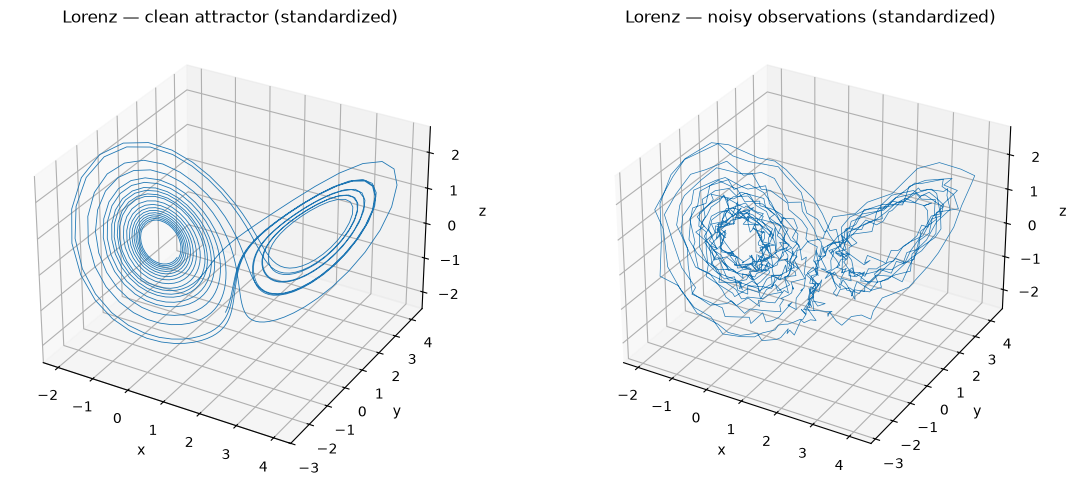

In [4]:
fig = plt.figure(figsize=(12, 5))
ax1 = fig.add_subplot(121, projection="3d")
a = lorenz_data["x_true"]
ax1.plot(a[:, 0], a[:, 1], a[:, 2], linewidth=0.6)
ax1.set_title("Lorenz — clean attractor (standardized)")
ax1.set_xlabel("x"); ax1.set_ylabel("y"); ax1.set_zlabel("z")

ax2 = fig.add_subplot(122, projection="3d")
b = lorenz_data["x_obs"]
ax2.plot(b[:, 0], b[:, 1], b[:, 2], linewidth=0.5)
ax2.set_title("Lorenz — noisy observations (standardized)")
ax2.set_xlabel("x"); ax2.set_ylabel("y"); ax2.set_zlabel("z")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "lorenz_attractor.png", dpi=160, bbox_inches="tight")
plt.show()


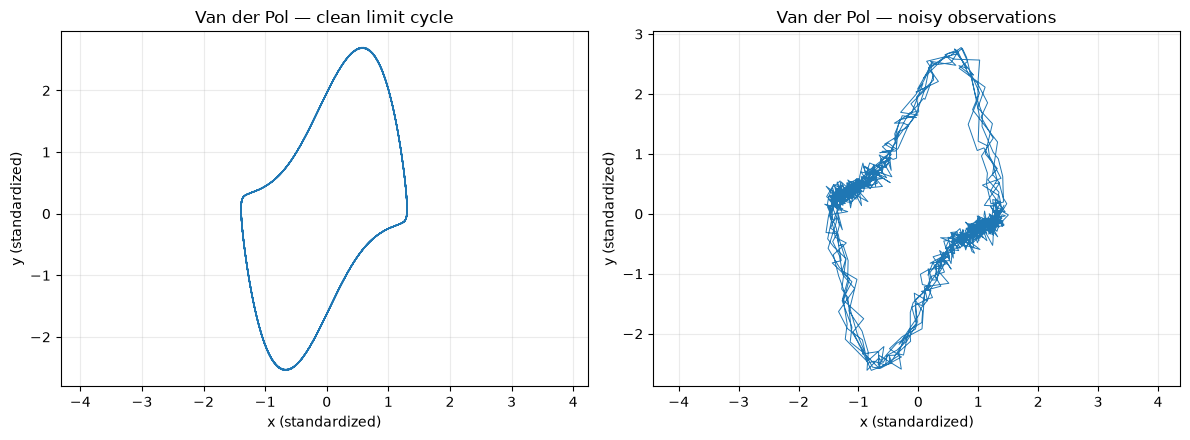

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
a = vdp_data["x_true"]
b = vdp_data["x_obs"]
axs[0].plot(a[:, 0], a[:, 1], linewidth=1)
axs[0].set_title("Van der Pol — clean limit cycle")
axs[1].plot(b[:, 0], b[:, 1], linewidth=0.7)
axs[1].set_title("Van der Pol — noisy observations")
for ax in axs:
    ax.set_xlabel("x (standardized)")
    ax.set_ylabel("y (standardized)")
    ax.axis("equal")
    ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "van_der_pol_limit_cycle.png", dpi=160, bbox_inches="tight")
plt.show()


## 5. Time-series inspection

We check how adding noise changes the observed time series. These plots are informative for data quality, but **time-series overlap alone is not a sufficient evaluation of chaotic dynamical-system reconstruction**.

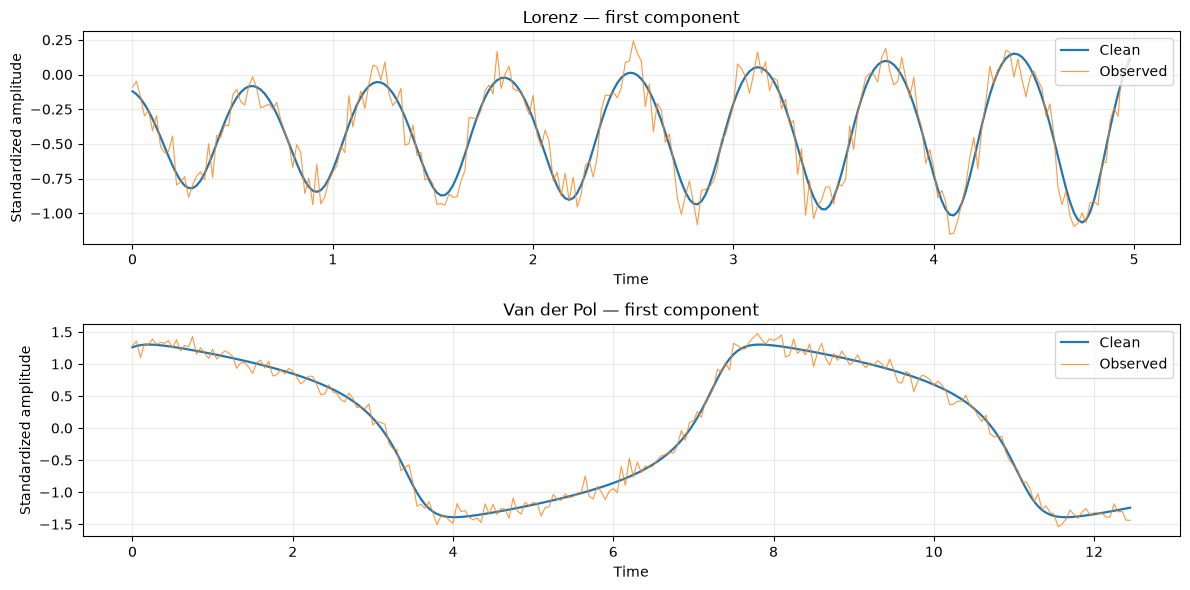

In [6]:
fig, axs = plt.subplots(2, 1, figsize=(12, 6), sharex=False)
for ax, label, data, channel in [
    (axs[0], "Lorenz", lorenz_data, 0),
    (axs[1], "Van der Pol", vdp_data, 0),
]:
    n = 250
    ax.plot(data["time"][:n], data["x_true"][:n, channel], label="Clean", linewidth=1.6)
    ax.plot(data["time"][:n], data["x_obs"][:n, channel], label="Observed", linewidth=0.8, alpha=0.8)
    ax.set_title(label + " — first component")
    ax.set_ylabel("Standardized amplitude")
    ax.set_xlabel("Time")
    ax.grid(alpha=0.25)
    ax.legend(loc="upper right")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "time_series.png", dpi=160, bbox_inches="tight")
plt.show()


## 6. Quality checks and reproducibility

We validate array shapes, numeric finiteness, normalized training statistics and reproducible observation noise. These checks should pass before fitting a model.

In [7]:
for name, d, dims in [("Lorenz", lorenz_data, 3), ("Van der Pol", vdp_data, 2)]:
    observed = d["x_obs"]
    ntrain = int(d["train_end"])
    assert observed.shape == (1000, dims)
    assert np.isfinite(observed).all()
    assert np.allclose(observed[:ntrain].mean(axis=0), 0, atol=1e-5)
    assert np.allclose(observed[:ntrain].std(axis=0), 1, atol=1e-5)
    noise_mse = float(np.mean((d["x_obs"] - d["x_true"])**2))
    print(f"{name}: T={len(observed)}, dim={dims}, train={ntrain}, noise MSE={noise_mse:.5f}")

again = make_dataset(lorenz_time, lorenz_states,
                     observation_noise_std=OBSERVATION_NOISE_STD,
                     train_fraction=TRAIN_FRACTION, seed=SEED)
assert np.array_equal(again["x_obs"], lorenz_data["x_obs"])
loaded = load_dataset(DATA_DIR / "lorenz_seed42.npz")
assert np.array_equal(loaded["x_obs"], lorenz_data["x_obs"])
print("All quality checks passed. Phase 1 completed.")


Lorenz: T=1000, dim=3, train=700, noise MSE=0.01011
Van der Pol: T=1000, dim=2, train=700, noise MSE=0.01004
All quality checks passed. Phase 1 completed.


## 7. Preliminary interpretation and next steps

**Expected qualitative observations (check the actual figures above):**

1. **Lorenz:** The clean trajectory follows a butterfly-shaped attractor; adding measurement noise blurs its geometry without changing the underlying deterministic ODE.
2. **Van der Pol:** The clean trajectory approaches/stays near a stable closed orbit; measurement noise makes the observed curve less smooth.
3. The same preprocessing and time indexing will be used for the LDS and PLRNN models.

**Important scientific distinction:** These visuals verify the data-generation pipeline. They do not demonstrate successful learning or dynamical reconstruction because no model has been trained yet.

**Next phase:** Fit an LDS baseline and then a PLRNN, examine one-step and multi-step predictions, and evaluate freely generated trajectories and attractor geometry.
